# MSE Budget for hourly releases over New Delhi

25 releases from 25.05.2015 00:00 UTC to 26.05.2015 00:00 UTC are evaluated over 10 days of backward simulation each. In total we are simulating 11 days.

For each release, the particle MSE change is compared with the contributions from sensible and latent surface heat fluxes as well as shortwave and longwave radiation.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import eccodes

In [2]:
################# ONLY CHANGE THIS PATH #####################################

run_dir = Path("/jetfs/scratch/gbrack/flexpart_output/new_delhi_30d_24h_hourly_releases_bigger_domain/")

################# DONT CHANGE ANYTHING HERE #################################

grid_files = sorted(run_dir.glob("grid_time*.nc"))
initial_files = sorted(run_dir.glob("partinit_*.nc"))
particle_files = sorted(run_dir.glob("partoutput_*.nc"))
particle_files = [
    path for path in particle_files
    if not path.name.endswith("_init.nc")
]

In [3]:
grid = xr.open_dataset(grid_files[0])
partinit = xr.open_dataset(initial_files[0])
particles = xr.open_mfdataset(particle_files)

In [4]:
release_overview = (
    partinit[["release", "time"]]
    .to_dataframe()
    .groupby("release")
    .agg(
        particles=("time", "size"),
        release_start=("time", "min"),
        release_end=("time", "max")
    )
)

for name in ["spec001_mr", "spec001_s22"]:
    print(name, grid[name].dims, grid[name].attrs.get("units"))

release_overview

spec001_mr ('nageclass', 'pointspec', 'time', 'height', 'latitude', 'longitude') s m3 kg-1
spec001_s22 ('nageclass', 'pointspec', 'time', 'height', 'latitude', 'longitude') s


,particles,release_start,release_end
release,,,
1.0,100000,2015-05-25 00:00:00,2015-05-25 00:00:00
2.0,100000,2015-05-25 01:00:00,2015-05-25 01:00:00
3.0,100000,2015-05-25 02:00:00,2015-05-25 02:00:00
4.0,100000,2015-05-25 03:00:00,2015-05-25 03:00:00
5.0,100000,2015-05-25 04:00:00,2015-05-25 04:00:00
6.0,100000,2015-05-25 05:00:00,2015-05-25 05:00:00
7.0,100000,2015-05-25 06:00:00,2015-05-25 06:00:00
8.0,100000,2015-05-25 07:00:00,2015-05-25 07:00:00
9.0,100000,2015-05-25 08:00:00,2015-05-25 08:00:00


## CALCULATE MSE DIFFERENCE FROM SENSITIVITIES

## CALCULATE MSE DIFFERENCE

In [5]:
## CALCULATE MSE

cp = 1004.6 # J / (kg K)
Lv = 2501000 # J / kg
g = 9.81 # m / s^2

def calculate_mse(state):
    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat
    )

    temperature_energy = cp * state.T.astype("float64")
    latent_energy = Lv * state.sh.astype("float64")
    potential_energy = g * (state.z.astype("float64") + ground_height)

    return temperature_energy + latent_energy + potential_energy

def calculate_mse_fine(state):
    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat
    )

    temperature_energy = cp * state.T.astype("float64")
    latent_energy = Lv * state.sh.astype("float64")
    potential_energy = g * (state.z.astype("float64") + ground_height)

    return xr.Dataset({
        "temperature": temperature_energy,
        "latent": latent_energy,
        "potential": potential_energy
    })

In [19]:
mse_results = []

for release, row in release_overview.iterrows():
    release_time = row["release_start"]
    earlier_time = release_time - pd.Timedelta(days=30)

    particle_ids = partinit.particle.where(partinit.release == release, drop=True)

    release_state = partinit.sel(particle=particle_ids)
    earlier_state = particles.sel(particle=particle_ids, time=earlier_time)

    mse_release = calculate_mse_fine(release_state).compute()
    mse_earlier = calculate_mse_fine(earlier_state).compute()

    valid = (np.isfinite(mse_release).to_array().all(dim="variable") & np.isfinite(mse_earlier).to_array().all(dim="variable"))

    delta_mse = (mse_release - mse_earlier).where(valid).mean(dim="particle", skipna=True)

    mse_results.append({
        "release": int(release),
        "release_time": release_time,
        "valid_particles": int(valid.sum().item()),
        "delta_cpT": delta_mse.temperature.item(),
        "delta_Lvq": delta_mse.latent.item(),
        "delta_pot": delta_mse.potential.item(),
        "delta_mse": delta_mse.to_array().sum(skipna=False).item()
    })

In [20]:
mse_budget = pd.DataFrame(mse_results).set_index("release")
mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse
release,,,,,,
1,2015-05-25 00:00:00,88440,41831.013678,10323.621851,-51807.596408,347.039121
2,2015-05-25 01:00:00,88235,41495.955091,11052.306564,-51641.504711,906.756945
3,2015-05-25 02:00:00,88308,42994.691921,12953.671653,-51791.570593,4156.792981
4,2015-05-25 03:00:00,88310,46161.460679,14275.582297,-52132.535509,8304.507467
5,2015-05-25 04:00:00,88160,48759.002429,14548.995588,-51920.395740,11387.602276
6,2015-05-25 05:00:00,88718,50999.047848,13116.460666,-51733.296851,12382.211662
7,2015-05-25 06:00:00,88637,52770.584061,11075.573916,-52124.582521,11721.575457
8,2015-05-25 07:00:00,88533,54073.014141,8686.081648,-52119.623536,10639.472253
9,2015-05-25 08:00:00,88650,54669.786131,6949.448509,-51791.324796,9827.909844


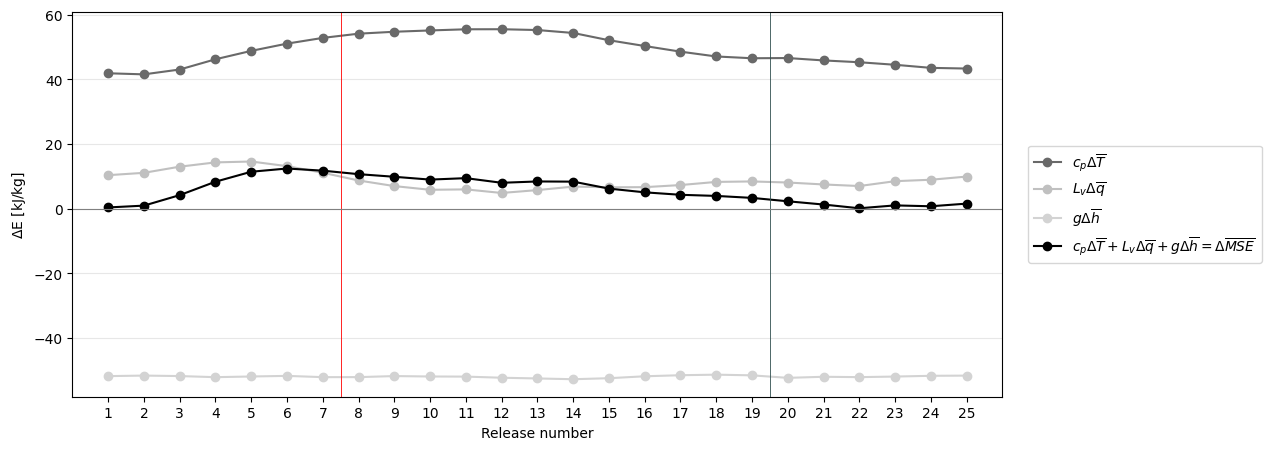

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

plotting_list = [
    ("delta_cpT", r"$c_p \Delta \overline{T}$", "dimgray"),
    ("delta_Lvq", r"$L_v \Delta \overline{q}$", "silver"),
    ("delta_pot", r"$g \Delta \overline{h}$", "lightgray"),
    ("delta_mse", r"$c_p \Delta \overline{T} + L_v \Delta \overline{q} + g \Delta \overline{h} = \Delta \overline{MSE}$", "black")
]

for column, label, color in plotting_list:
    ax.plot(
        mse_budget.index, mse_budget[column] / 1000,
        marker="o", label=label, color=color,
    )

ax.axvline(7.5, color="red", linewidth=0.6)
ax.axvline(19.5, color="darkslategrey", linewidth=0.6)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Release number")
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days')

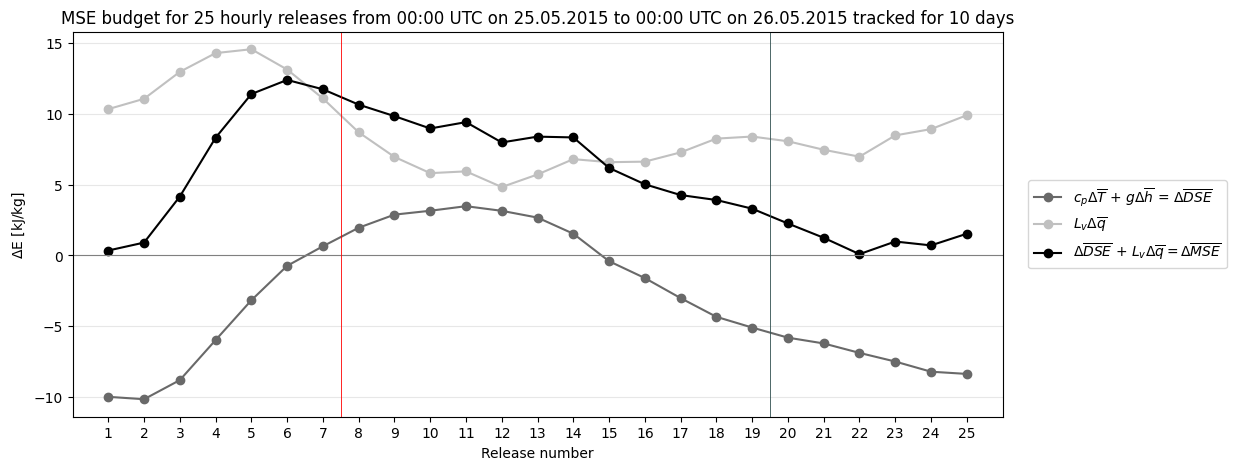

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(7.5, color="red", linewidth=0.6)
ax.axvline(19.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days")

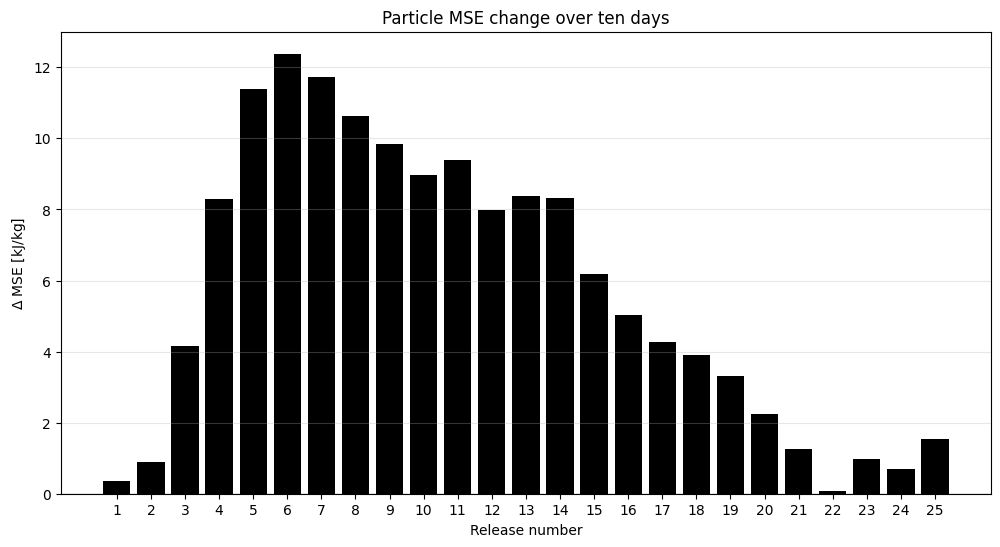

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.bar(mse_budget.index, mse_budget["delta_mse"] / 1000, color="black")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("Particle MSE change over ten days")
ax.grid(axis="y", alpha=0.3)

## SURFACE FLUXES FOR EACH RELEASE

In [24]:
surface_file = Path("/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_2015_04_05_06.nc")
surface = xr.open_dataset(surface_file).rename({"valid_time": "time"})

surface = surface.assign_coords(time=surface.time - np.timedelta64(1, "h"))

surface_aligned = surface.sel(time=grid.time,latitude=grid.latitude,longitude=grid.longitude)

In [25]:
surface_source = xr.Dataset({
    "sensible": -surface_aligned.sshf / (3600 * 100),
    "latent": -surface_aligned.slhf / (3600 * 100)
})

In [26]:
## calculate surface contribution for each release over the 10 days

surface_results = []

for release, row in release_overview.iterrows():
    release_time = row["release_start"]
    earlier_time = release_time - pd.Timedelta(days=30)

    interval_mask = ((grid.time >= earlier_time) & (grid.time < release_time))

    sensitivity = (
        grid.spec001_mr.isel(pointspec=int(release) - 1, nageclass=0, drop=True).sel(height=100, drop=True).sel(time=grid.time[interval_mask])
    )

    assert sensitivity.sizes["time"] == 240*3  # maximum age of particles

    source = surface_source.sel(time=sensitivity.time)
    source, s = xr.align(source, sensitivity, join="exact")

    contributions = xr.where(s == 0, 0.0, source * s).sum(
        dim=["time", "latitude", "longitude"],
        skipna=False
    ).compute()

    surface_results.append({
        "release": int(release),
        "sensible": contributions.sensible.item(),
        "latent": contributions.latent.item()
    })

surface_budget = pd.DataFrame(surface_results).set_index("release")

mse_budget["sfc_sensible"] = surface_budget["sensible"]
mse_budget["sfc_latent"] = surface_budget["latent"]
mse_budget["sfc_total"] = surface_budget["sensible"] + surface_budget["latent"]

surface_budget

KeyboardInterrupt: 

In [27]:
mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse,sfc_sensible,sfc_latent,sfc_total
release,,,,,,,,,
1,2015-05-25 00:00:00,57962,40976.244150,10453.535762,-50329.960662,1099.819250,6755.502051,13722.059874,20477.561925
2,2015-05-25 01:00:00,57409,40710.566087,11145.483517,-50172.857598,1683.192006,7059.245533,14152.676311,21211.921844
3,2015-05-25 02:00:00,57735,42123.919137,13033.015726,-50292.044224,4864.890640,7042.554149,14541.975679,21584.529828
4,2015-05-25 03:00:00,57649,45243.583651,14335.471784,-50451.020042,9128.035393,9168.029604,15321.291934,24489.321538
5,2015-05-25 04:00:00,57153,48149.856845,14746.705204,-50601.998115,12294.563933,10519.065873,15403.697091,25922.762964
6,2015-05-25 05:00:00,58194,50282.734987,13163.407934,-50326.536011,13119.606910,12373.499017,14988.238682,27361.737699
7,2015-05-25 06:00:00,58454,51583.608854,11099.360741,-50168.771749,12514.197846,12416.443628,14688.053356,27104.496984
8,2015-05-25 07:00:00,57830,53257.299675,8744.856608,-50785.677872,11216.478412,12466.490043,14648.854900,27115.344943
9,2015-05-25 08:00:00,57434,53934.806900,7037.765196,-50467.609267,10504.962829,12753.317047,14848.507159,27601.824206


Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days')

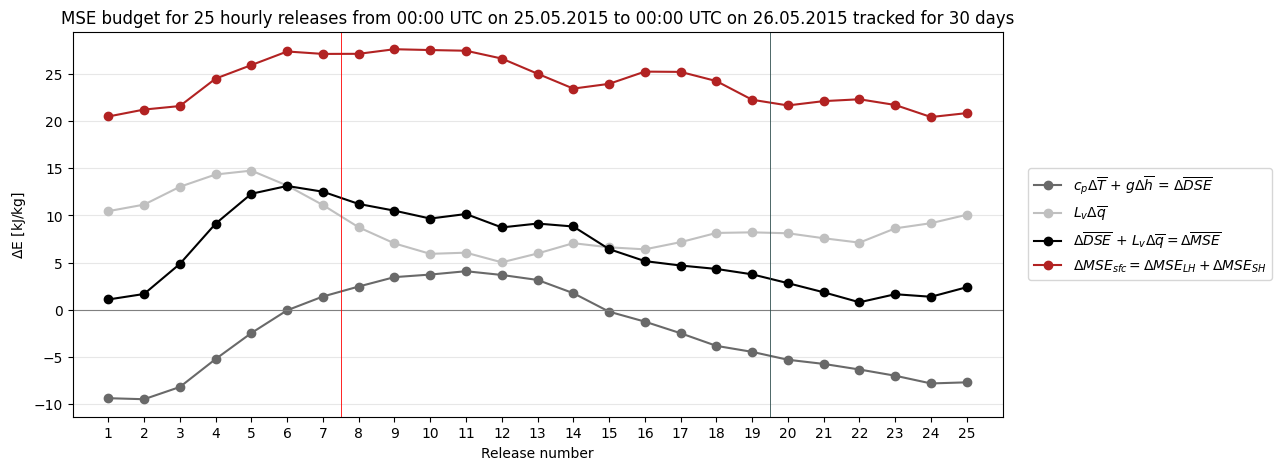

In [57]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.plot(mse_budget.index,
        mse_budget.sfc_total / 1000,
        marker="o", label=r'$\Delta MSE_{sfc} = \Delta MSE_{LH} + \Delta MSE_{SH}$', color="firebrick")

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(7.5, color="red", linewidth=0.6)
ax.axvline(19.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days")

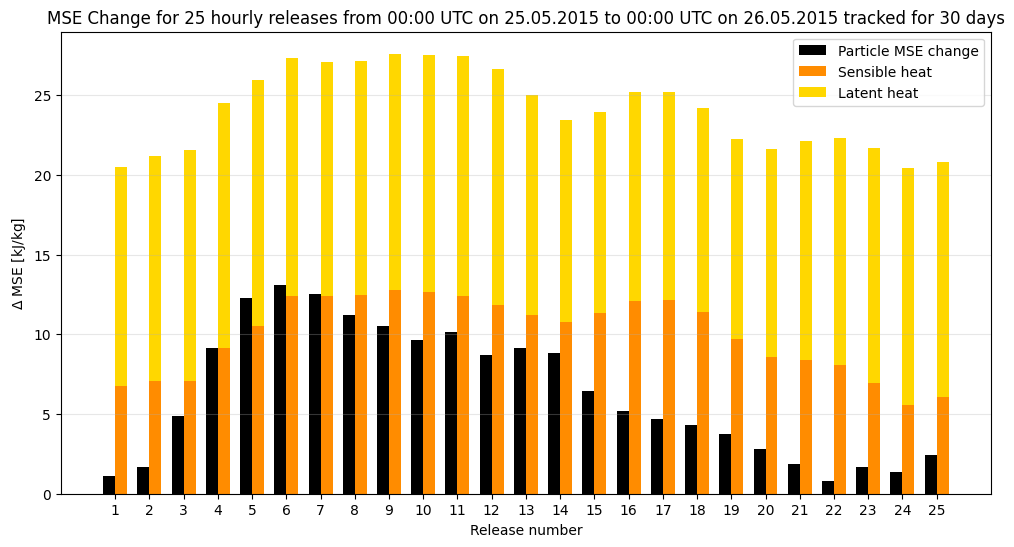

In [53]:
width = 0.35

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
ax.bar(mse_budget.index - width / 2, 
       mse_budget["delta_mse"] / 1000,
       width, 
       label="Particle MSE change", 
       color="black")

ax.bar(mse_budget.index + width / 2, 
       mse_budget["sfc_sensible"] / 1000,
       width, 
       label="Sensible heat", 
       color="darkorange")
ax.bar(mse_budget.index + width / 2, 
       mse_budget["sfc_latent"] / 1000,
       width, 
       bottom=mse_budget["sfc_sensible"] / 1000,
       label="Latent heat", 
       color="gold")

ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("MSE Change for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days")
ax.grid(axis="y", alpha=0.3)
ax.legend()

## RADIATION FOR EACH RELEASE, NOW WITH OUR NEW SENSITIVITY MEASURE

We use:

$$
\Delta h_{\mathrm{rad}, r} = \sum_{t,k,y,x} S_{22, r} c_p \overline{\dot{T}_{\mathrm{SW}} + \dot{T}_{\mathrm{LW}}}
$$

In [33]:
radiation_dir = Path("/jetfs/scratch/gbrack/MSC/ERA5_FLEXPART_global_0.5deg_42vertlayers/2015")

radiation = xr.open_mfdataset(
    [radiation_dir / f"radiation_fp_2015{m}.nc" for m in ["04", "05", "06"]],
    combine="by_coords",
    data_vars="minimal",
    coords="minimal",
    join="exact"
)

radiation_selected = radiation[["sw_source", "lw_source"]].sel(
    time=grid.time.values,
    height=grid.height.values,
    latitude=grid.latitude.values,
    longitude=grid.longitude.values
)

In [34]:
radiation_selected

<xarray.Dataset> Size: 24GB
Dimensions:    (time: 744, height: 42, latitude: 230, longitude: 420)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2015-05-25T23:00:00 ... 2015-04-25
  * height     (height) float64 336B 100.0 250.0 500.0 ... 3e+04 4e+04 5e+04
  * latitude   (latitude) float64 2kB -30.0 -29.5 -29.0 -28.5 ... 83.5 84.0 84.5
  * longitude  (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
Data variables:
    sw_source  (time, height, latitude, longitude) float32 12GB dask.array<chunksize=(1, 6, 60, 60), meta=np.ndarray>
    lw_source  (time, height, latitude, longitude) float32 12GB dask.array<chunksize=(1, 6, 60, 60), meta=np.ndarray>
Attributes:
    vertical_method:  Geometric-thickness-weighted mean,constant values withi...
    geometry_time:    Radiation interval end
    cp:               1004.6

In [43]:
releases = release_overview.index.to_numpy(dtype=int)
release_times = pd.DatetimeIndex(release_overview["release_start"])
earlier_times = release_times - pd.Timedelta(days=30)
grid_times = pd.DatetimeIndex(grid.time.values)

s22 = grid.spec001_s22.isel(nageclass=0, drop=True)
sources, s22 = xr.align(radiation_selected, s22, join="exact")

# both sums for every release
totals = np.zeros((len(releases), 2), dtype=np.float64)
hours_used = np.zeros(len(releases), dtype=int)

for i, hour in enumerate(grid_times):
    active = np.flatnonzero((earlier_times <= hour) & (hour < release_times))
    if active.size == 0:
        continue

    # load one hour of radiation and use for all active releases
    rad_hour = sources.isel(time=i).to_array("component").transpose(
        "height", "latitude", "longitude", "component"
    ).to_numpy().reshape(-1, 2).astype(np.float64)

    sens_hour = s22.isel(
        time=i, pointspec=releases[active] - 1
    ).transpose("pointspec", "height", "latitude", "longitude").to_numpy().reshape(active.size, -1).astype(np.float64)

    totals[active] += sens_hour @ rad_hour
    hours_used[active] += 1

    if (i + 1) % 24 == 0:
        print(f"{i+1}/{len(grid_times)} hours calculated")

np.testing.assert_array_equal(hours_used, np.full(len(releases), 720))

radiation_budget = pd.DataFrame(
    totals,
    index=pd.Index(releases, name="release"),
    columns=["rad_sw", "rad_lw"]
)
radiation_budget["rad_net"] = radiation_budget.rad_sw + radiation_budget.rad_lw

radiation_budget

24/744 hours calculated
48/744 hours calculated
72/744 hours calculated
96/744 hours calculated
120/744 hours calculated
144/744 hours calculated
168/744 hours calculated
192/744 hours calculated
216/744 hours calculated
240/744 hours calculated
264/744 hours calculated
288/744 hours calculated
312/744 hours calculated
336/744 hours calculated
360/744 hours calculated
384/744 hours calculated
408/744 hours calculated
432/744 hours calculated
456/744 hours calculated
480/744 hours calculated
504/744 hours calculated
528/744 hours calculated
552/744 hours calculated
576/744 hours calculated
600/744 hours calculated
624/744 hours calculated
648/744 hours calculated
672/744 hours calculated
696/744 hours calculated
720/744 hours calculated
744/744 hours calculated


,rad_sw,rad_lw,rad_net
release,,,
1,23131.176269,-43604.316277,-20473.140008
2,23198.047115,-43474.084652,-20276.037538
3,23018.089832,-43234.088720,-20215.998888
4,23024.241323,-43003.130213,-19978.888890
5,23184.984082,-42980.803580,-19795.819498
6,23638.978100,-42739.369014,-19100.390914
7,23547.510623,-42483.211312,-18935.700689
8,23503.221524,-42024.129062,-18520.907538
9,23617.722373,-41723.737997,-18106.015624


In [46]:
# define columns
columns = ["rad_sw", "rad_lw", "rad_net"]

missing = mse_budget.index.difference(radiation_budget.index)
assert missing.empty, f"Strahlungsbudget fehlt für Releases: {missing.tolist()}"

# combine pandas dataframes
mse_budget[columns] = radiation_budget[columns]

mse_budget["sources_total"] = mse_budget["sfc_total"] + mse_budget["rad_net"]
mse_budget["residual"] = mse_budget["delta_mse"] - mse_budget["sources_total"]

mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse,sfc_sensible,sfc_latent,sfc_total,rad_sw,rad_lw,rad_net,sources_total,residual
release,,,,,,,,,,,,,,
1,2015-05-25 00:00:00,57962,40976.244150,10453.535762,-50329.960662,1099.819250,6755.502051,13722.059874,20477.561925,23131.176269,-43604.316277,-20473.140008,4.421917,1095.397333
2,2015-05-25 01:00:00,57409,40710.566087,11145.483517,-50172.857598,1683.192006,7059.245533,14152.676311,21211.921844,23198.047115,-43474.084652,-20276.037538,935.884307,747.307700
3,2015-05-25 02:00:00,57735,42123.919137,13033.015726,-50292.044224,4864.890640,7042.554149,14541.975679,21584.529828,23018.089832,-43234.088720,-20215.998888,1368.530941,3496.359699
4,2015-05-25 03:00:00,57649,45243.583651,14335.471784,-50451.020042,9128.035393,9168.029604,15321.291934,24489.321538,23024.241323,-43003.130213,-19978.888890,4510.432648,4617.602745
5,2015-05-25 04:00:00,57153,48149.856845,14746.705204,-50601.998115,12294.563933,10519.065873,15403.697091,25922.762964,23184.984082,-42980.803580,-19795.819498,6126.943466,6167.620468
6,2015-05-25 05:00:00,58194,50282.734987,13163.407934,-50326.536011,13119.606910,12373.499017,14988.238682,27361.737699,23638.978100,-42739.369014,-19100.390914,8261.346785,4858.260125
7,2015-05-25 06:00:00,58454,51583.608854,11099.360741,-50168.771749,12514.197846,12416.443628,14688.053356,27104.496984,23547.510623,-42483.211312,-18935.700689,8168.796295,4345.401552
8,2015-05-25 07:00:00,57830,53257.299675,8744.856608,-50785.677872,11216.478412,12466.490043,14648.854900,27115.344943,23503.221524,-42024.129062,-18520.907538,8594.437405,2622.041006
9,2015-05-25 08:00:00,57434,53934.806900,7037.765196,-50467.609267,10504.962829,12753.317047,14848.507159,27601.824206,23617.722373,-41723.737997,-18106.015624,9495.808581,1009.154248


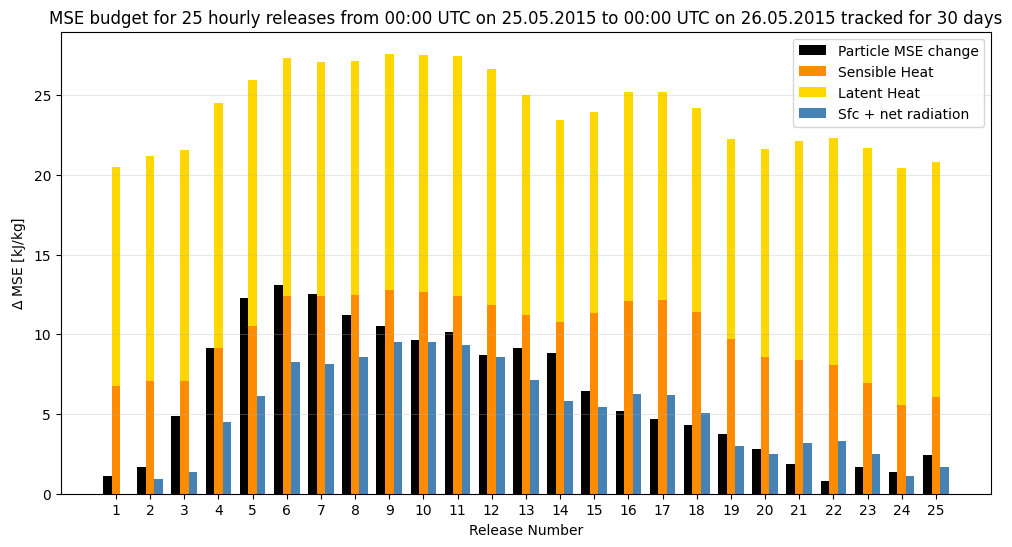

In [52]:
# lets look at it on a bar plot again

width = 0.25

fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.bar(
    mse_budget.index - width, mse_budget["delta_mse"] / 1000,
    width, color="black", label="Particle MSE change"
)

ax.bar(
    mse_budget.index, mse_budget["sfc_sensible"] / 1000,
    width, color="darkorange", label="Sensible Heat"
)
ax.bar(
    mse_budget.index, mse_budget["sfc_latent"] / 1000,
    width, bottom=mse_budget["sfc_sensible"] / 1000,
    color="gold", label="Latent Heat"
)

ax.bar(
    mse_budget.index + width, mse_budget["sources_total"] / 1000,
    width, color="steelblue", label="Sfc + net radiation"
)

ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release Number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days")
ax.grid(axis="y", alpha=0.3)
ax.legend()

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days')

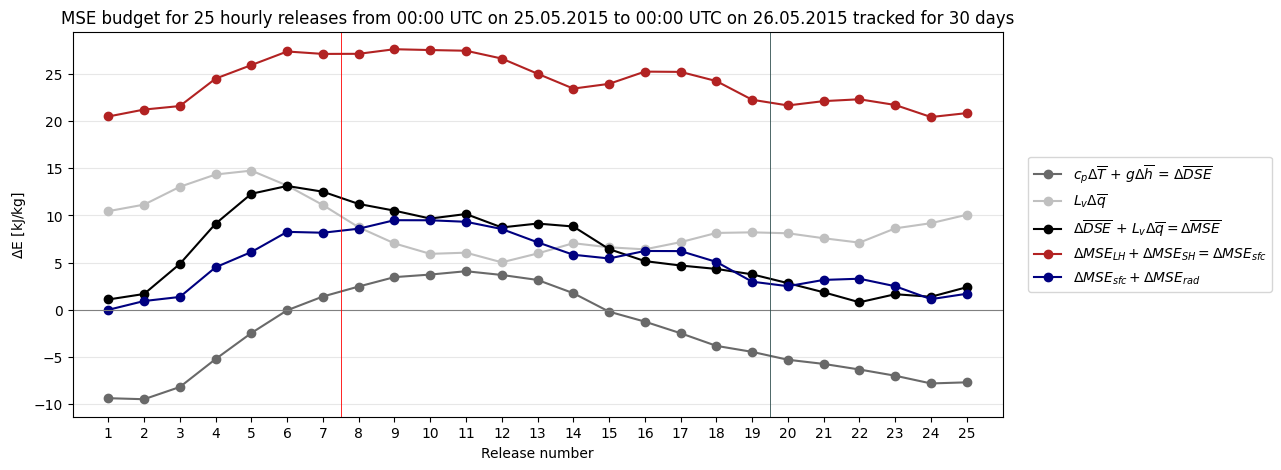

In [58]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.plot(mse_budget.index,
        mse_budget.sfc_total / 1000,
        marker="o", label=r"$\Delta MSE_{LH} + \Delta MSE_{SH} = \Delta MSE_{sfc}$", color="firebrick")

ax.plot(mse_budget.index,
        mse_budget.sources_total / 1000,
        marker="o", label=r"$\Delta MSE_{sfc} + \Delta MSE_{rad}$", color="navy")

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(7.5, color="red", linewidth=0.6)
ax.axvline(19.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days")

Text(0.5, 1.0, 'Residual')

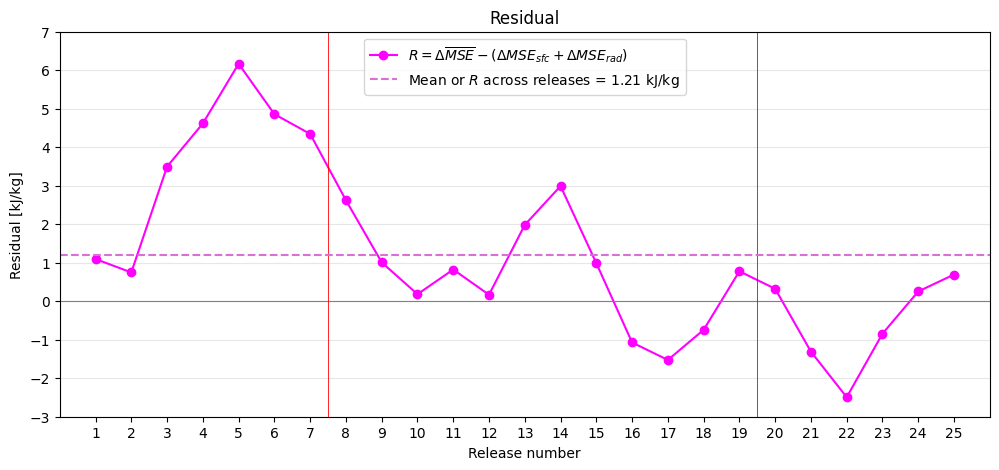

In [67]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index,
        mse_budget.residual / 1000,
        marker="o", label=r"$R = \Delta \overline{MSE} - (\Delta MSE_{sfc} + \Delta MSE_{rad})$",
        color="magenta"
    )

ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_yticks(np.arange(-3, 8, 1))
ax.set_ylim(-3, 7)
ax.set_ylabel("Residual [kJ/kg]")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(7.5, color="red", linewidth=0.6)
ax.axvline(19.5, color="darkslategrey", linewidth=0.6)
ax.axhline(mse_budget.residual.mean() / 1000, color="orchid", linestyle="--", label=rf"Mean or $R$ across releases = {(mse_budget.residual.mean() / 1000):.2f} kJ/kg")
ax.grid(axis="y", alpha=0.3)
ax.legend()
ax.set_title("Residual")

In [64]:
mean_abs_residual = abs(mse_budget.residual).mean()

In [66]:
mean_abs_residual

1845.2882702000975